# SADF + RSI Basket Trading Model

---

## Strategy Overview

| Parameter | Value |
|-----------|-------|
| **Universe** | 9 risk-on assets + 1 risk-off (TLT) |
| **Timeframe** | Daily (1D) |
| **Ranking** | Expanding SADF statistic and RSI (14-day) |
| **Selection** | Top 3 assets by SADF where SADF > 0.0 and RSI > 30 |
| **Risk-Off** | TLT (20Y Treasury ETF) — absorbs unused weight |
| **Rebalancing** | Biweekly (every 10 trading days) |
| **Allocation** | Equal-weight among selected; remainder → TLT |
| **Lookahead** | 1-day signal shift — signal on day $t$, trade on day $t+1$ |

### Strategy Logic

1. Compute an **expanding SADF statistic** for each of the 9 risk-on assets to detect explosive regimes.
2. Compute **RSI (14)** for each asset to gauge momentum.
3. Every 10 trading days, **rank** all assets by their lagged SADF statistic.
4. **Select top 3** with $SADF > 0.0$ and $RSI > 30$ (explosive + positive momentum).
5. **Equal-weight** the selected assets (33.3% each).
6. If fewer than 3 qualify, allocate remaining weight to **TLT** (risk-off).
7. If none qualify, go **100% TLT**.
8. **Shift signals by 1 day** to prevent lookahead bias.

### Asset Universe

| # | Ticker | Asset | Role |
|---|--------|-------|------|
| 1 | BTC-USD | Bitcoin | Risk-on |
| 2 | QQQ | Nasdaq 100 ETF | Risk-on |
| 3 | SPY | S&P 500 ETF | Risk-on |
| 4 | AAPL | Apple | Risk-on |
| 5 | TSLA | Tesla | Risk-on |
| 6 | GLD | Gold ETF | Risk-on |
| 7 | NVDA | NVIDIA | Risk-on |
| 8 | AMZN | Amazon | Risk-on |
| 9 | XLE | Energy Sector ETF | Risk-on |
| 10 | **TLT** | **20Y Treasury ETF** | **Risk-off** |



In [1]:
# ============================================================
#  IMPORTS & CONFIGURATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (16, 7),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.facecolor': 'white',
})

# ── STRATEGY PARAMETERS ──────────────────────────────────────
ALL_TICKERS   = ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA',
                 'GLD', 'NVDA', 'AMZN', 'XLE', 'TLT']
RISK_OFF      = 'TLT'
RISK_ON       = [t for t in ALL_TICKERS if t != RISK_OFF]

START_DATE    = '2018-01-01'
END_DATE      = '2025-01-01'
SADF_MIN_WIN  = 100         # Min expanding window
RSI_WINDOW    = 14
REBAL_PERIOD  = 10          # Biweekly
TOP_N         = 3           # Assets to hold
MIN_SADF      = 0.0         # Explosivity threshold
MIN_RSI       = 30          # Momentum threshold
SIGNAL_LAG    = 1           # 1-day shift to prevent lookahead
INITIAL_CAP   = 100_000

print(f'Risk-on    : {len(RISK_ON)} assets — {RISK_ON}')
print(f'Risk-off   : {RISK_OFF}')
print(f'Period     : {START_DATE} to {END_DATE}')
print(f'SADF min win : {SADF_MIN_WIN}d | RSI win : {RSI_WINDOW}d | Rebalance: every {REBAL_PERIOD}d')
print(f'Signal lag : {SIGNAL_LAG}d (lookahead protection)')
print(f'Selection  : top {TOP_N} with SADF > {MIN_SADF} & RSI > {MIN_RSI}, remainder -> {RISK_OFF}')


c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Risk-on    : 9 assets — ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA', 'GLD', 'NVDA', 'AMZN', 'XLE']
Risk-off   : TLT
Period     : 2018-01-01 to 2025-01-01
SADF min win : 100d | RSI win : 14d | Rebalance: every 10d
Signal lag : 1d (lookahead protection)
Selection  : top 3 with SADF > 0.0 & RSI > 30, remainder -> TLT


## 1. Data Download

In [2]:
# ============================================================
#  DOWNLOAD DAILY CLOSE PRICES
# ============================================================

close_prices = pd.DataFrame()
for ticker in ALL_TICKERS:
    df = yf.download(ticker, start=START_DATE, end=END_DATE,
                     progress=False, auto_adjust=True)
    if len(df) > 0:
        close_prices[ticker] = df['Close'].squeeze()

close_prices = close_prices.ffill().dropna()
returns = close_prices.pct_change().dropna()

print(f'Date range  : {close_prices.index[0].date()} to {close_prices.index[-1].date()}')
print(f'Trading days: {len(close_prices)}\n')

for t in close_prices.columns:
    role = 'RISK-OFF' if t == RISK_OFF else 'risk-on'
    pct = (close_prices[t].iloc[-1] / close_prices[t].iloc[0] - 1) * 100
    print(f'  {t:>8} [{role:>8}] | {close_prices[t].iloc[0]:>10,.2f} -> {close_prices[t].iloc[-1]:>10,.2f} | {pct:>+8.1f}%')


Date range  : 2018-01-02 to 2024-12-31
Trading days: 2556

   BTC-USD [ risk-on] |  14,982.10 ->  93,429.20 |   +523.6%
       QQQ [ risk-on] |     150.41 ->     508.65 |   +238.2%
       SPY [ risk-on] |     237.21 ->     579.28 |   +144.2%
      AAPL [ risk-on] |      40.30 ->     249.06 |   +517.9%
      TSLA [ risk-on] |      21.37 ->     403.84 |  +1789.9%
       GLD [ risk-on] |     125.15 ->     242.13 |    +93.5%
      NVDA [ risk-on] |       4.93 ->     134.25 |  +2624.0%
      AMZN [ risk-on] |      59.45 ->     219.39 |   +269.0%
       XLE [ risk-on] |      25.92 ->      41.45 |    +59.9%
       TLT [RISK-OFF] |     100.19 ->      83.29 |    -16.9%


### Normalized Price Chart

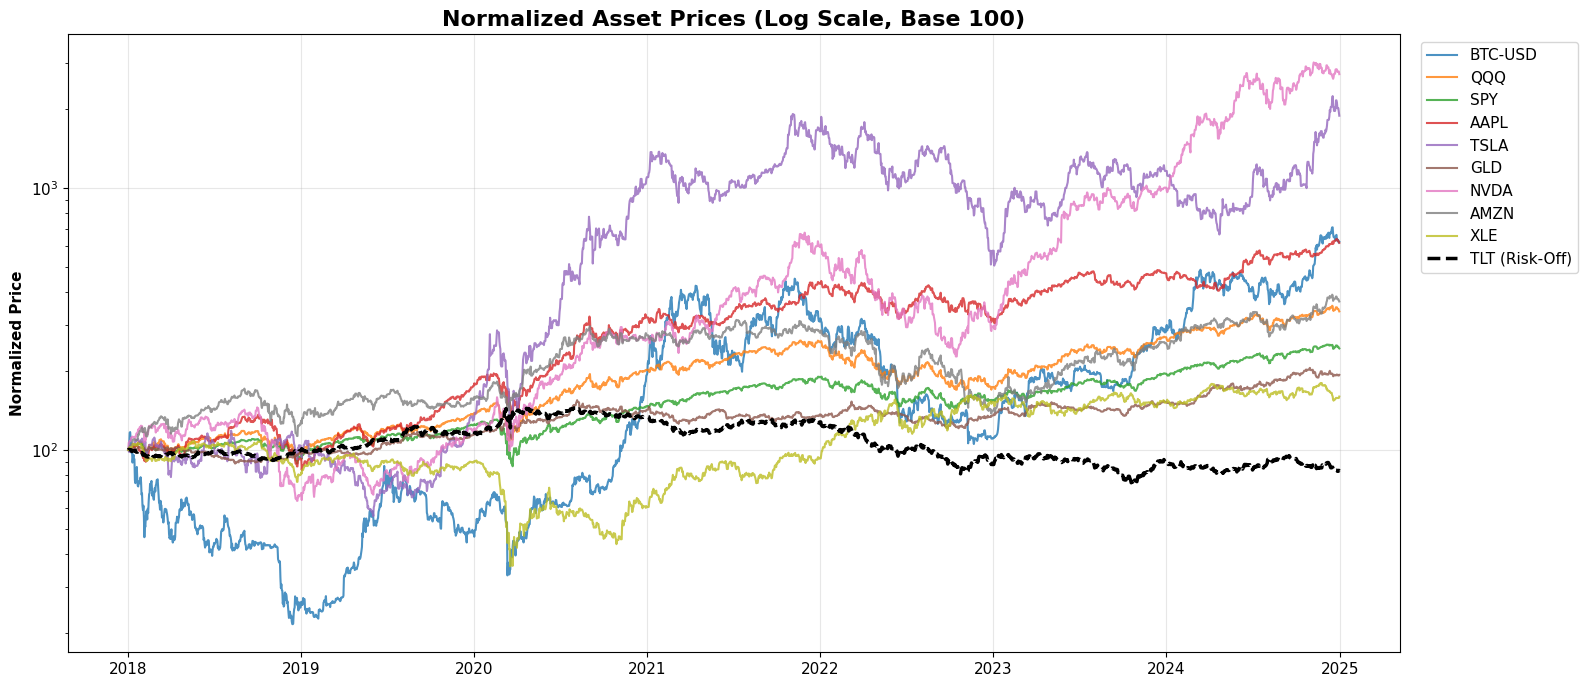

In [3]:
norm_prices = close_prices / close_prices.iloc[0] * 100

fig, ax = plt.subplots(figsize=(16, 7))
for t in RISK_ON:
    ax.plot(norm_prices.index, norm_prices[t], label=t, lw=1.5, alpha=0.8)
    
ax.plot(norm_prices.index, norm_prices[RISK_OFF], label=f'{RISK_OFF} (Risk-Off)', 
        lw=2.5, color='black', linestyle='--')

ax.set_yscale('log')
ax.set_title('Normalized Asset Prices (Log Scale, Base 100)', fontsize=16)
ax.set_ylabel('Normalized Price')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 2. SADF and RSI Calculation

Calculate the expanding SADF sequence to detect bubble explosivity, and calculate a standard 14-day RSI for momentum confirmation.

In [4]:
# ============================================================
#  CALCULATE SADF & RSI
# ============================================================

def calc_rsi(series, window=14):
    delta = series.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calculate_sadf_sequence(series, min_window=100):
    y = series.values
    n = len(y)
    sequence = np.full(n, np.nan)
    
    dy = np.diff(y)
    y_lag = y[:-1]
    
    for t in range(min_window, n):
        dy_window = dy[:t]
        y_lag_window = y_lag[:t]
        
        X = sm.add_constant(y_lag_window)
        try:
            results = sm.OLS(dy_window, X).fit()
            sequence[t] = results.tvalues[1]
        except:
            sequence[t] = np.nan
            
    return pd.Series(sequence, index=series.index)

print(f"Calculating rolling RSI({RSI_WINDOW})...")
rsi_df = pd.DataFrame(index=close_prices.index, columns=RISK_ON)
for ticker in RISK_ON:
    rsi_df[ticker] = calc_rsi(close_prices[ticker], window=RSI_WINDOW)

print(f"Calculating expanding SADF (min_window={SADF_MIN_WIN})...")
sadf_df = pd.DataFrame(index=close_prices.index, columns=RISK_ON)
for ticker in tqdm(RISK_ON, desc="Computing SADF"):
    sadf_df[ticker] = calculate_sadf_sequence(np.log(close_prices[ticker]), min_window=SADF_MIN_WIN)

sadf_df.dropna(how='all', inplace=True)
rsi_df = rsi_df.loc[sadf_df.index]


Calculating rolling RSI(14)...
Calculating expanding SADF (min_window=100)...


Computing SADF: 100%|██████████| 9/9 [00:04<00:00,  2.08it/s]


## 3. Signal Matrix Generation

Generate target weights by ranking testing SADF and filtering via RSI. Rebalance every N days.

In [5]:
# ============================================================
#  GENERATE TARGET WEIGHTS
# ============================================================

signals = pd.DataFrame(0, index=sadf_df.index, columns=RISK_ON)
valid_mask = (sadf_df > MIN_SADF) & (rsi_df > MIN_RSI)

rebal_days = np.arange(0, len(sadf_df), REBAL_PERIOD)

print("Generating rebalance signals...")
for i in range(len(sadf_df)):
    if i in rebal_days:
        day_valid = valid_mask.iloc[i]
        if day_valid.any():
            day_sadf = sadf_df.iloc[i][day_valid]
            # Select top N highest SADF
            top_assets = day_sadf.nlargest(TOP_N).index
            signals.iloc[i][top_assets] = 1
    else:
        if i > 0:
            signals.iloc[i] = signals.iloc[i-1]

# Apply Signal Lag!
shifted_signals = signals.shift(SIGNAL_LAG).fillna(0)

# Calculate weights
row_sums = shifted_signals.sum(axis=1)
# weight per selected asset is  1/TOP_N if selected >= TOP_N else 1/row_sums then scaled down by proportion. Actually, equal-weight among selected is 1/TOP_N if we strictly hold TOP_N slots. If fewer than TOP_N, each gets 1/TOP_N and the rest goes to TLT.
weights_on = shifted_signals.div(TOP_N)

# The remaining unallocated weight goes to the risk-off asset
tlt_weight = 1.0 - weights_on.sum(axis=1)

weights = weights_on.copy()
weights[RISK_OFF] = tlt_weight

print("Weights generation complete. Sample of target weights:")
display(weights.tail(10))


Generating rebalance signals...
Weights generation complete. Sample of target weights:


,BTC-USD,QQQ,SPY,AAPL,TSLA,GLD,NVDA,AMZN,XLE,TLT
Date,,,,,,,,,,
2024-12-22,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-23,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-24,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-25,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-26,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-27,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-28,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-29,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667
2024-12-30,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.666667


## 4. Portfolio Backtest

Apply weights to daily returns and compound to create an equity curve. Compare with Buy & Hold SPY.

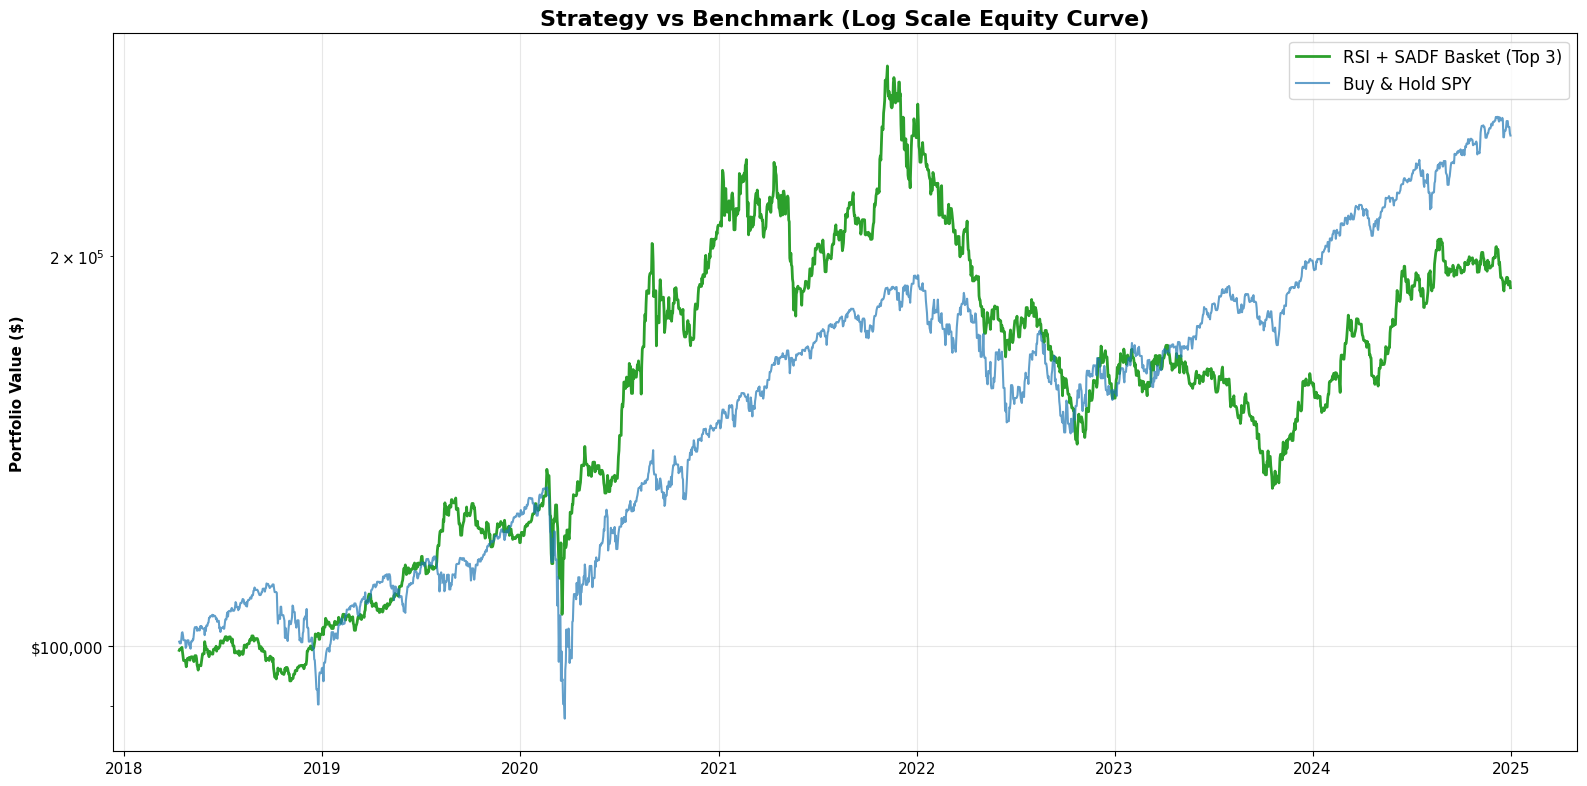

In [6]:
# ============================================================
#  BACKTESTING & EQUITY CURVES
# ============================================================

# Aligned returns covering the weight period
aligned_returns = returns.loc[weights.index]

port_return = (weights * aligned_returns).sum(axis=1)
cum_port = (1 + port_return).cumprod()

spy_return = aligned_returns['SPY']
cum_spy = (1 + spy_return).cumprod()

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(cum_port.index, cum_port * INITIAL_CAP, label=f'RSI + SADF Basket (Top {TOP_N})', color='#2ca02c', lw=2)
ax.plot(cum_spy.index, cum_spy * INITIAL_CAP, label='Buy & Hold SPY', color='#1f77b4', alpha=0.7, lw=1.5)

ax.set_yscale('log')
ax.set_title('Strategy vs Benchmark (Log Scale Equity Curve)', fontsize=16)
ax.set_ylabel('Portfolio Value ($)')
ax.legend(fontsize=12)

import matplotlib.ticker as ticker
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}'))
plt.tight_layout()
plt.show()


## 5. Performance Metrics & Comparative Analysis

In [7]:
# ============================================================
#  CALCULATE METRICS
# ============================================================

def calc_metrics(ret_series):
    comp_ret = (1 + ret_series).prod() - 1
    # Annualized based on ~252 trading days/yr
    ann_ret = (1 + comp_ret) ** (252 / len(ret_series)) - 1
    ann_vol = ret_series.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol if ann_vol != 0 else 0
    
    cum_series = (1 + ret_series).cumprod()
    rolling_max = cum_series.cummax()
    drawdown = (cum_series - rolling_max) / rolling_max
    mdd = drawdown.min()
    
    return {
        'Total Return': f"{comp_ret*100:.1f}%",
        'CAGR': f"{ann_ret*100:.1f}%",
        'Ann. Volatility': f"{ann_vol*100:.1f}%",
        'Sharpe Ratio': f"{sharpe:.2f}",
        'Max Drawdown': f"{mdd*100:.1f}%"
    }

metrics_df = pd.DataFrame({
    'RSI + SADF Basket': calc_metrics(port_return),
    'SPY B&H': calc_metrics(spy_return)
})

display(metrics_df)


,RSI + SADF Basket,SPY B&H
Total Return,89.1%,147.9%
CAGR,6.8%,9.8%
Ann. Volatility,19.4%,16.1%
Sharpe Ratio,0.35,0.61
Max Drawdown,-52.8%,-33.7%


### Rolling 6-Month Sharpe Ratio

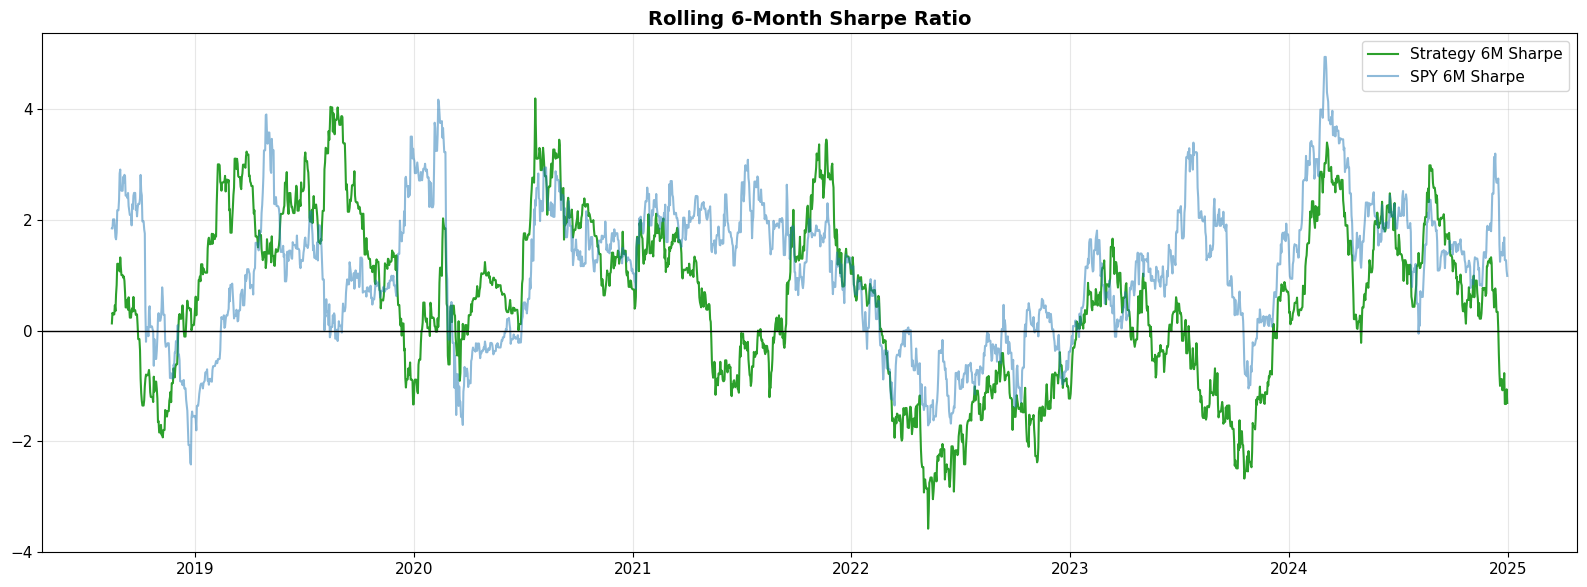

In [8]:
# ============================================================
#  ROLLING SHARPE
# ============================================================

roll_win = 126  # ~6 months

roll_ret_port = port_return.rolling(roll_win).mean() * 252
roll_vol_port = port_return.rolling(roll_win).std() * np.sqrt(252)
roll_sharpe_port = roll_ret_port / roll_vol_port

roll_ret_spy = spy_return.rolling(roll_win).mean() * 252
roll_vol_spy = spy_return.rolling(roll_win).std() * np.sqrt(252)
roll_sharpe_spy = roll_ret_spy / roll_vol_spy

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(roll_sharpe_port.index, roll_sharpe_port, label='Strategy 6M Sharpe', color='#2ca02c')
ax.plot(roll_sharpe_spy.index, roll_sharpe_spy, label='SPY 6M Sharpe', color='#1f77b4', alpha=0.5)

ax.axhline(0, color='black', lw=1)
ax.set_title('Rolling 6-Month Sharpe Ratio', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()


### Annual Returns Comparison

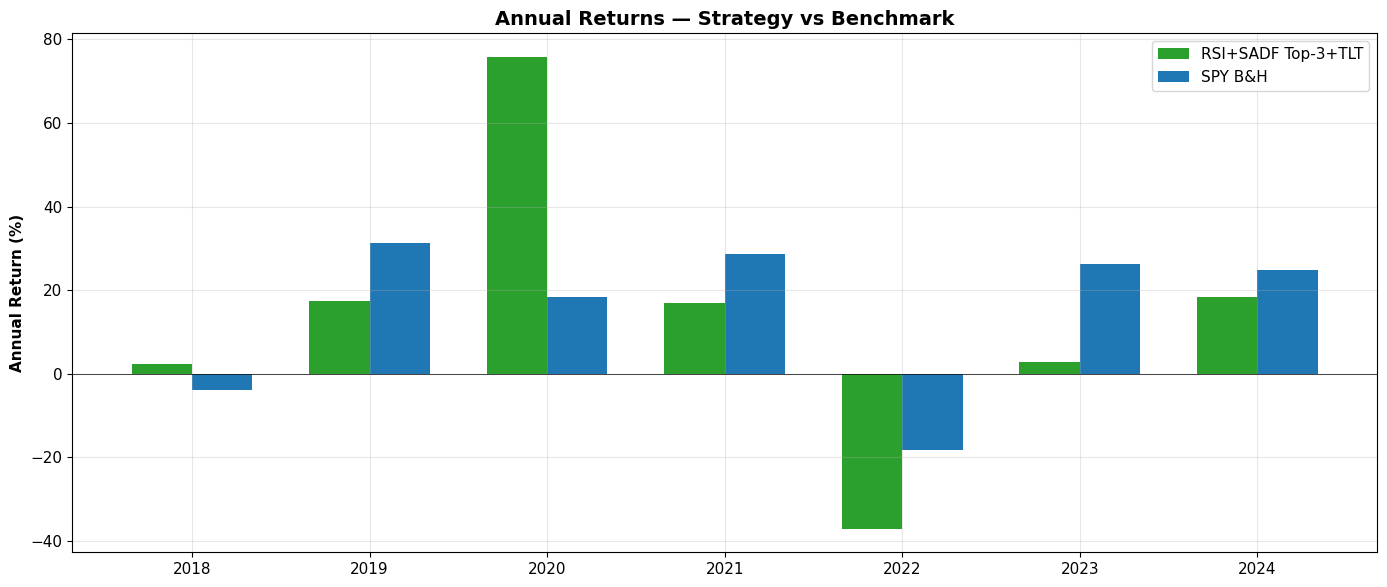

In [9]:
# ============================================================
#  ANNUAL RETURNS
# ============================================================

ann_port = port_return.resample('YE').apply(lambda x: (1+x).prod()-1)
ann_spy = spy_return.resample('YE').apply(lambda x: (1+x).prod()-1)

yrs = ann_port.index.year
x = np.arange(len(yrs))

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - 0.17, ann_port.values * 100, 0.34, label=f'RSI+SADF Top-{TOP_N}+TLT', color='#2ca02c')
ax.bar(x + 0.17, ann_spy.values * 100, 0.34, label='SPY B&H', color='#1f77b4')

ax.set_xticks(x)
ax.set_xticklabels(yrs)
ax.set_ylabel('Annual Return (%)')
ax.axhline(0, color='black', lw=0.5)
ax.set_title('Annual Returns — Strategy vs Benchmark', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()
